# Regional and local lineament extraction: West Java

This notebook repeats the West Java use case of the Pylineament paper: the same DEM is processed with two parameter settings,
one for **regional** lineaments (long and sparse) and one for **local** lineaments (short and dense).

What is covered:

- the input DEM
- the two parameter settings
- extraction with `ln.dem_to_shp` (parallel, with image splitting)
- maps of the whole area and of a zoom around Bandung
- number and length of the lineaments, rose diagrams
- length–frequency (power-law) plot and fractal dimension D

**Data.** `srtmgl1_westjava.tif`: NASA Shuttle Radar Topography Mission, Global 1 arc-second (SRTMGL1, ≈ 30 m),
downloaded from OpenTopography (https://portal.opentopography.org/), mosaic of West Java and Banten
(105.05°–108.95° E, 5.47°–7.88° S, 14,022 × 8,694 px, EPSG:4326). The file is a lossless DEFLATE-compressed copy
(33 MB instead of 244 MB); the elevation values are unchanged.

**Run time.** The local extraction takes a few minutes on an 8-core computer; the regional one about one minute.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from rasterio.enums import Resampling
from rasterio.windows import from_bounds

import pylineament as ln
from importlib.metadata import version

DEM = 'srtmgl1_westjava.tif'
OUT = 'westjava_output'           # extracted shapefiles are written here
os.makedirs(OUT, exist_ok=True)
print('pylineament', version('pylineament'))

pylineament 1.1.0


## Input DEM

14022 x 8694 px; EPSG:4326 ; cell size 1.0 arc-seconds
extent (lon/lat): [105.054, -7.881, 108.949, -5.466]


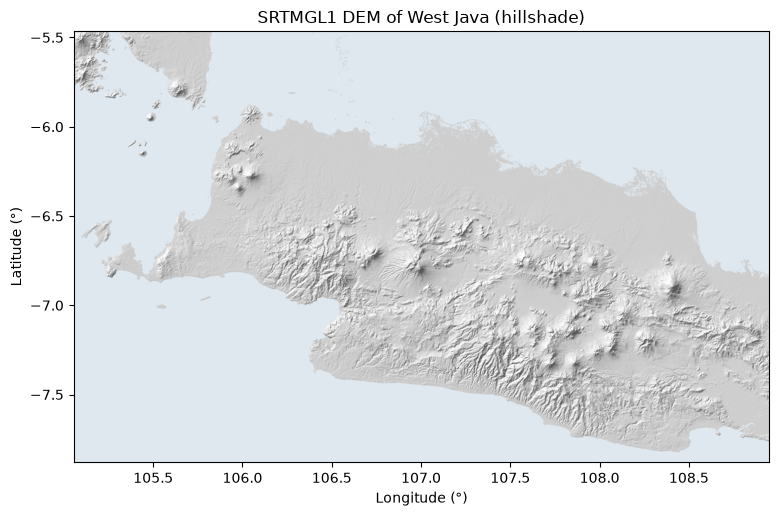

In [2]:
with rasterio.open(DEM) as src:
    print(src.width, 'x', src.height, 'px;', src.crs, '; cell size', round(src.res[0] * 3600, 2), 'arc-seconds')
    print('extent (lon/lat):', [round(v, 3) for v in src.bounds])
    BOUNDS = tuple(src.bounds)


def hillshade(bounds, width=1400, vex=3):
    """Display hillshade (azimuth 315, altitude 45) of a lon/lat box, read at reduced resolution."""
    with rasterio.open(DEM) as src:
        win = from_bounds(*bounds, transform=src.transform)
        h = int(width * win.height / win.width)
        z = src.read(1, window=win, out_shape=(h, width), resampling=Resampling.average).astype(float)
        dx = src.res[0] * win.width / width * 111320 * np.cos(np.radians(np.mean(bounds[1::2])))
        dy = src.res[1] * win.height / h * 110570
    z[z < -1000] = np.nan
    gy, gx = np.gradient(np.nan_to_num(z) * vex, dy, dx)
    az, alt = np.radians(315), np.radians(45)
    hs = (np.sin(alt) + np.cos(alt) * (np.sin(az) * -gx + np.cos(az) * gy)) / np.sqrt(1 + gx ** 2 + gy ** 2)
    hs = 0.35 + 0.65 * np.clip(hs, 0, 1)
    hs[np.isnan(z) | (z <= 0)] = np.nan          # sea and NoData
    return hs


HS_FULL = hillshade(BOUNDS)
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.set_facecolor('#dfe8ef')
ax.imshow(HS_FULL, cmap='gray', vmin=0, vmax=1, extent=(BOUNDS[0], BOUNDS[2], BOUNDS[1], BOUNDS[3]))
ax.set_title('SRTMGL1 DEM of West Java (hillshade)')
ax.set_xlabel('Longitude (°)'); ax.set_ylabel('Latitude (°)')
plt.show()

## Parameter settings

Different parameters extract different lineament properties (Table 6 of the paper):

| | Local | Regional |
|---|---|---|
| Img_size (`split_size`) | 500 px | 500 px |
| Z_multiplier (`z_multip`) | 1 | 1 |
| Downsampling (`downscale`) | 0.6 | 0.3 |
| Eps (`eps`) | 1.2 | 1.6 |
| Thresh (`thresh`) | 20 | 60 |
| Min_seg (`min_dist`) | 10 | 10 |
| Seg_len (`seg_len`) | 10 | 10 |

The **regional** setting downscales each tile more and uses a larger `eps` and `thresh`: edge points are joined into long
lineaments and short ones are removed. The **local** setting keeps more of the DEM resolution and uses smaller `eps` and
`thresh`, so short lineaments are kept.

In [3]:
SETTINGS = {
    'regional': dict(split_size=500, z_multip=1, downscale=0.3, eps=1.6, thresh=60, min_dist=10, seg_len=10),
    'local':    dict(split_size=500, z_multip=1, downscale=0.6, eps=1.2, thresh=20, min_dist=10, seg_len=10),
}
N_JOBS = os.cpu_count()

## Extraction

In [4]:
lines, seconds = {}, {}
for name, p in SETTINGS.items():
    t0 = time.perf_counter()
    lines[name] = ln.dem_to_shp(DEM, tempfolder=f'temp_{name}', shp_name=os.path.join(OUT, f'westjava_{name}.shp'),
                                n_jobs=N_JOBS, **p)
    seconds[name] = time.perf_counter() - t0
    print(f'{name:8s}: {len(lines[name]):,} lineaments in {seconds[name]:.0f} s ({N_JOBS} worker processes)')

regional: 8,774 lineaments in 72 s (8 worker processes)


local   : 71,830 lineaments in 251 s (8 worker processes)


## Maps: whole area and zoom

The zoom box covers the area around Bandung.

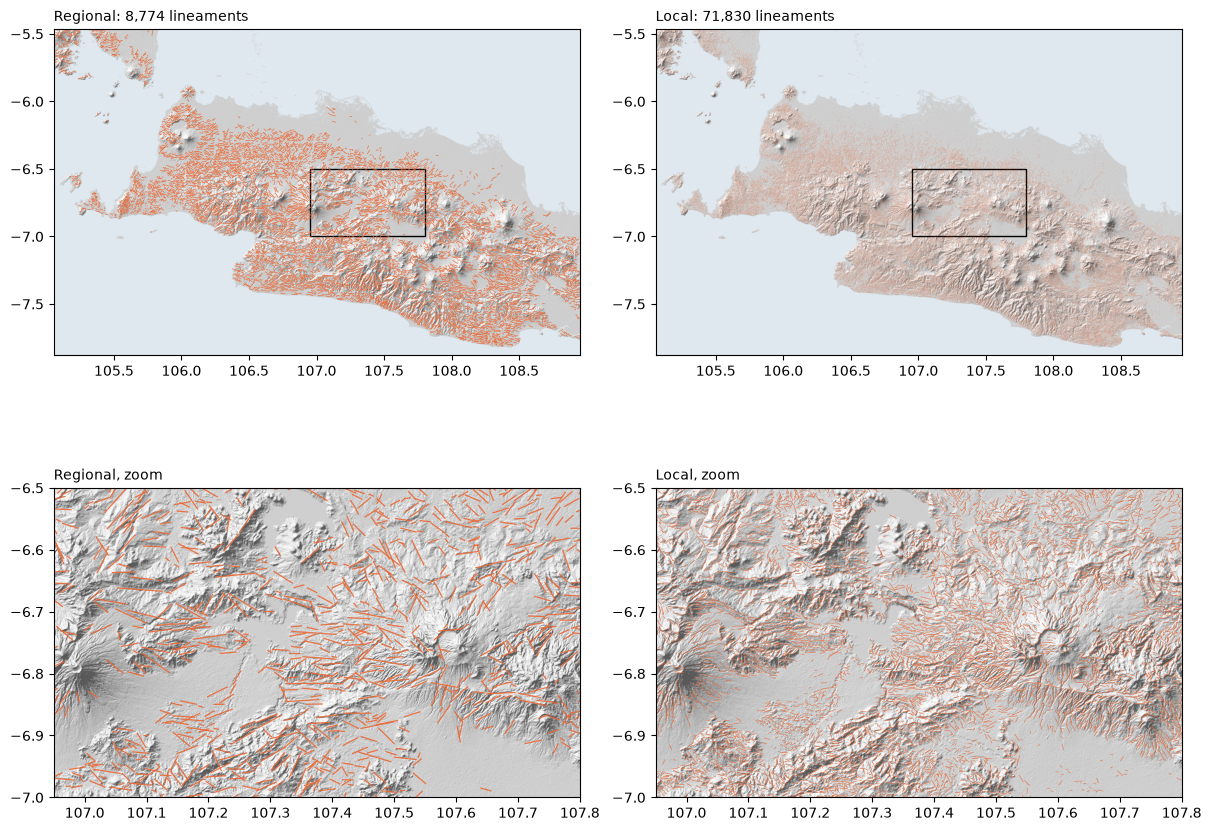

In [5]:
ZOOM = (106.95, -7.0, 107.8, -6.5)        # lon_min, lat_min, lon_max, lat_max
HS_ZOOM = hillshade(ZOOM)


def segments(df):
    return np.stack([df[['min_x', 'min_y']].values, df[['max_x', 'max_y']].values], axis=1)


def map_panel(ax, df, bounds, hs, title, lw, alpha):
    ax.set_facecolor('#dfe8ef')
    ax.imshow(hs, cmap='gray', vmin=0, vmax=1, extent=(bounds[0], bounds[2], bounds[1], bounds[3]))
    ax.add_collection(LineCollection(segments(df), colors='#eb6834', linewidths=lw, alpha=alpha))
    ax.set_xlim(bounds[0], bounds[2]); ax.set_ylim(bounds[1], bounds[3]); ax.set_aspect('equal')
    ax.set_title(title, loc='left', fontsize=10)


fig, axs = plt.subplots(2, 2, figsize=(12, 9), layout='constrained')
for j, name in enumerate(SETTINGS):
    df = lines[name]
    lw, alpha = (0.5, 0.9) if name == 'regional' else (0.12, 0.6)
    map_panel(axs[0, j], df, BOUNDS, HS_FULL, f'{name.capitalize()}: {len(df):,} lineaments', lw, alpha)
    axs[0, j].add_patch(Rectangle(ZOOM[:2], ZOOM[2] - ZOOM[0], ZOOM[3] - ZOOM[1], fill=False, ec='black'))
    inz = ((df[['min_x', 'max_x']].max(axis=1) >= ZOOM[0]) & (df[['min_x', 'max_x']].min(axis=1) <= ZOOM[2]) &
           (df[['min_y', 'max_y']].max(axis=1) >= ZOOM[1]) & (df[['min_y', 'max_y']].min(axis=1) <= ZOOM[3]))
    map_panel(axs[1, j], df[inz], ZOOM, HS_ZOOM, f'{name.capitalize()}, zoom', 0.9 if name == 'regional' else 0.4, 0.9)
plt.show()

## Number, length and orientation of the lineaments

Line coordinates are in degrees (EPSG:4326), so lengths are converted to kilometres with the haversine formula.

In [6]:
def length_km(df):
    lon0, lat0, lon1, lat1 = (np.radians(df[c].values) for c in ('min_x', 'min_y', 'max_x', 'max_y'))
    a = np.sin((lat1 - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin((lon1 - lon0) / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))


def azimuth(df):
    dx = (df.max_x - df.min_x).values * np.cos(np.radians(df.min_y.values))
    return np.degrees(np.arctan2(dx, (df.max_y - df.min_y).values)) % 180


summary = pd.DataFrame({name: {'lineaments': len(df), 'median length (km)': np.median(length_km(df)),
                               'max length (km)': length_km(df).max(), 'total length (km)': length_km(df).sum(),
                               'run time (s)': seconds[name]}
                        for name, df in lines.items()}).T.round(2)
summary

,lineaments,median length (km),max length (km),total length (km),run time (s)
regional,8774.0,2.05,16.38,19891.98,71.77
local,71830.0,0.51,8.24,56247.03,251.49


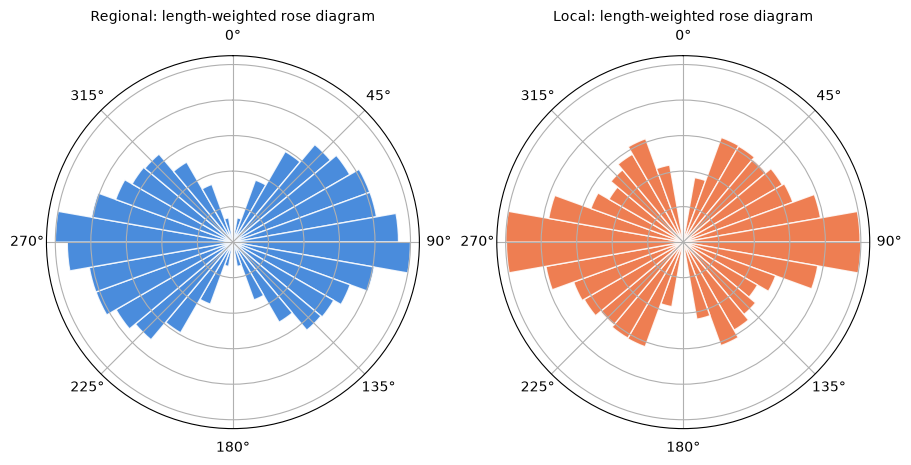

In [7]:
bins = np.radians(np.arange(0, 361, 10))
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5), subplot_kw={'projection': 'polar'}, layout='constrained')
for ax, (name, df), color in zip(axs, lines.items(), ['#2a78d6', '#eb6834']):
    az, L = azimuth(df), length_km(df)
    h = np.histogram(np.radians(np.r_[az, az + 180]), bins=bins, weights=np.r_[L, L])[0]
    ax.bar(bins[:-1], h / h.max(), width=np.radians(10), align='edge', color=color, alpha=0.85, edgecolor='white')
    ax.set_theta_zero_location('N'); ax.set_theta_direction(-1); ax.set_yticklabels([])
    ax.set_title(f'{name.capitalize()}: length-weighted rose diagram', fontsize=10)
plt.show()

## Length–frequency plot and fractal dimension

Same procedure as in the paper (Section 6.2):

1. lineament length r in metres;
2. 20 length classes, spaced evenly on a logarithmic scale between the shortest and the longest lineament;
3. cumulative number N(r) of lineaments longer than each class;
4. only the steep part of the curve is used: classes where N(r) is still more than 90 % of all lineaments are excluded,
   because that flat part reflects the minimum length set by the parameters;
5. least-squares fit of log N(r) = −D log r + C.

D is useful to compare the two settings; it should not be compared with values obtained with other parameters or methods.

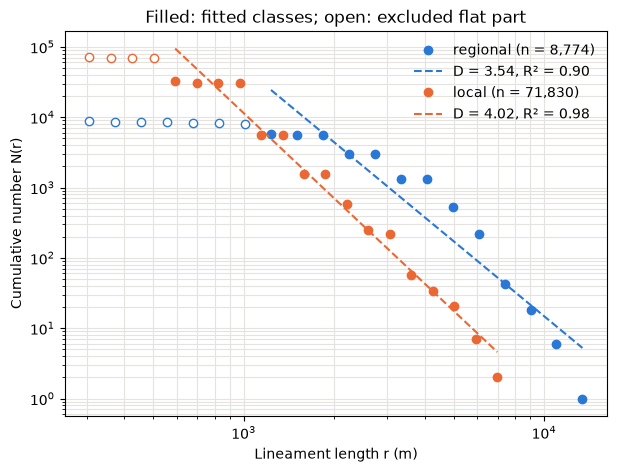

,D,C,R2,fitted from (m)
regional,3.54,15.32,0.90,1232.35
local,4.02,16.12,0.98,591.21


In [8]:
def powerlaw(L, n_bins=20, frac=0.9):
    edges = np.logspace(np.log10(L.min()), np.log10(L.max()), n_bins + 1)[:-1]
    N = np.array([(L > e).sum() for e in edges])
    keep = N > 0
    r, N = edges[keep], N[keep]
    steep = N <= frac * len(L)
    slope, C = np.polyfit(np.log10(r[steep]), np.log10(N[steep]), 1)
    pred = slope * np.log10(r[steep]) + C
    y = np.log10(N[steep])
    r2 = 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)
    return r, N, steep, -slope, C, r2


fig, ax = plt.subplots(figsize=(7, 5))
rows = {}
for (name, df), color in zip(lines.items(), ['#2a78d6', '#eb6834']):
    r, N, steep, D, C, r2 = powerlaw(length_km(df) * 1000)
    rows[name] = {'D': D, 'C': C, 'R2': r2, 'fitted from (m)': r[steep].min()}
    ax.loglog(r[steep], N[steep], 'o', color=color, label=f'{name} (n = {len(df):,})')
    ax.loglog(r[~steep], N[~steep], 'o', mfc='white', mec=color)
    rr = np.array([r[steep].min(), r[steep].max()])
    ax.loglog(rr, 10 ** (C - D * np.log10(rr)), '--', color=color, label=f'D = {D:.2f}, R² = {r2:.2f}')
ax.set_xlabel('Lineament length r (m)'); ax.set_ylabel('Cumulative number N(r)')
ax.grid(which='both', color='#e4e3df'); ax.legend(frameon=False)
ax.set_title('Filled: fitted classes; open: excluded flat part')
plt.show()
pd.DataFrame(rows).T.round(2)

## Notes

- The extracted lineaments are saved as Shapefiles in `westjava_output/` and can be opened in any GIS.
- Run times depend on the computer and the number of worker processes (`n_jobs`).
- Since the change to six unique hillshade directions (0°–150°), results can differ very slightly from runs with the
  earlier twelve directions (0°–330°); the opposite directions gave identical edges.